# YOLO11 vs YOLO26 + Fine-Tuning

**Mission:** Discover whether a newer pretrained model recognizes more objects, then teach a YOLO detector a **new class** using annotated examples.


**Sources:** [YOLO26](https://docs.ultralytics.com/models/yolo26/), [fine-tuning](https://docs.ultralytics.com/guides/finetuning-guide/), [dataset format](https://docs.ultralytics.com/datasets/detect/).

## 0. Colab setup + Google Drive


In [1]:
%pip -q install -U ultralytics pillow matplotlib pandas pyyaml
import torch, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from IPython.display import display
from google.colab import drive
from ultralytics import YOLO

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
print('PyTorch:', torch.__version__, 'GPU:', torch.cuda.is_available())
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

PyTorch: 2.11.0+cu130 GPU: True


## 1. Load a real image from Google Drive (or upload from your computer)

Put a JPEG or PNG in Google Drive and set `IMAGE_PATH` to its location.

In [3]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


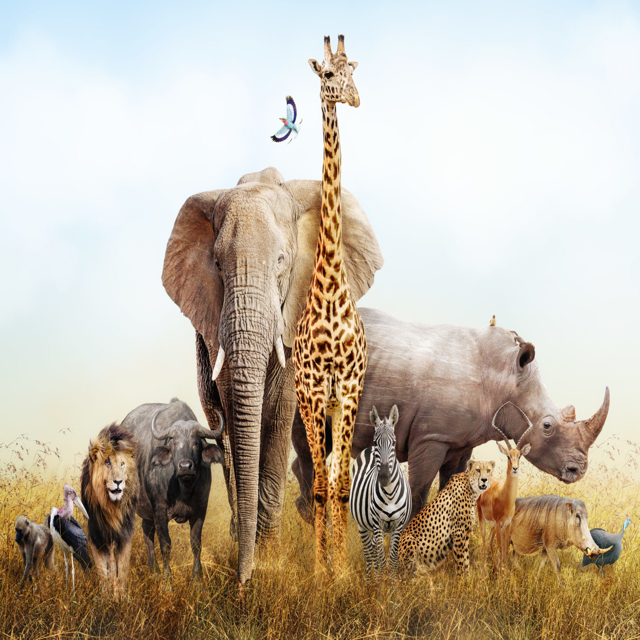

In [4]:
from PIL import Image

# Enter your image path
image_path = '/content/drive/MyDrive/wildlife.jpg'

# Load and display the image
image = Image.open(image_path).convert('RGB')
# Resize image
image = image.resize((640, 640))

display(image)

## 2. Load two pretrained models
We use **nano** sizes for a reasonably fair, Colab-friendly comparison. The first run may download weights and take longer.

In [5]:
models={'YOLO11n':YOLO('yolo11n.pt'),'YOLO26n':YOLO('yolo26n.pt')}

## 3. Same image, same settings
Record detections and approximate inference time. **Do not treat confidence as probability of correctness**, and do not treat a single image as a benchmark.

YOLO11n {'zebra': 1, 'elephant': 2, 'bird': 3, 'cow': 2}


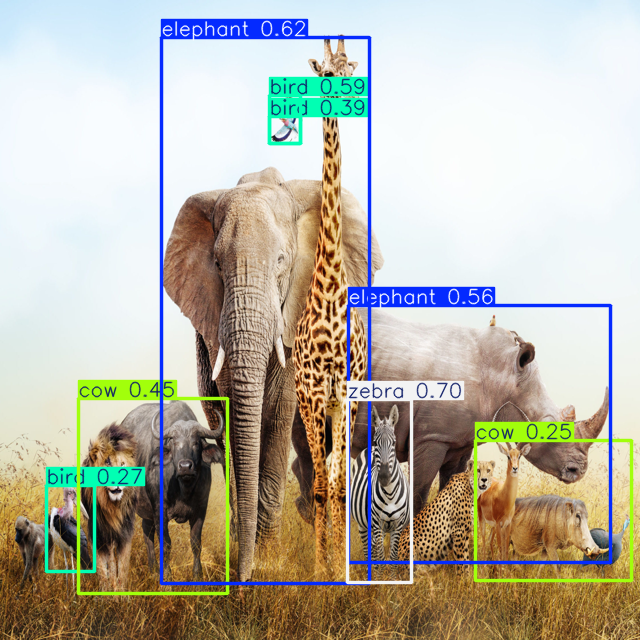

YOLO26n {'zebra': 1, 'cow': 1, 'elephant': 1, 'giraffe': 1}


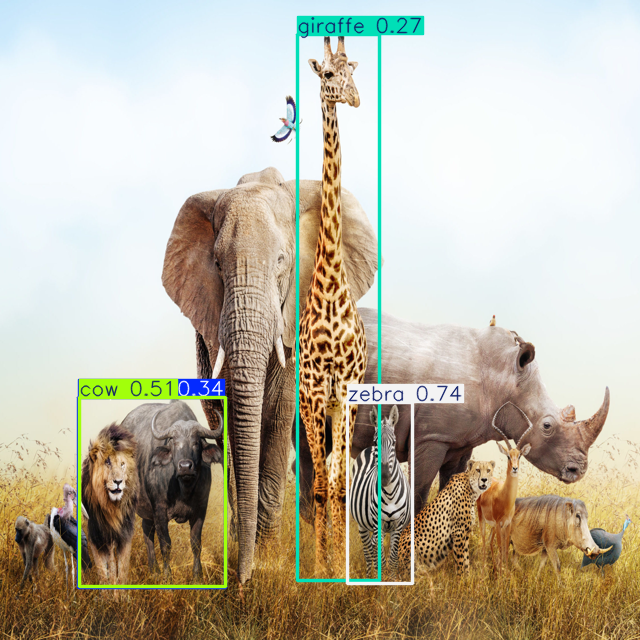

,model,detections,wall_time_ms,classes_found
0,YOLO11n,8,22.0,"{'zebra': 1, 'elephant': 2, 'bird': 3, 'cow': 2}"
1,YOLO26n,4,14.0,"{'zebra': 1, 'cow': 1, 'elephant': 1, 'giraffe..."


In [6]:
CONF=0.25; SIZE=640
outputs={}; records=[]
for name,model in models.items():
    # Warm up separately from timed run
    _=model.predict(image,conf=CONF,imgsz=SIZE,device=DEVICE,verbose=False)
    start=time.perf_counter()
    result=model.predict(image,conf=CONF,imgsz=SIZE,device=DEVICE,verbose=False)[0]
    elapsed=(time.perf_counter()-start)*1000
    outputs[name]=result
    counts={}
    for cls in result.boxes.cls.cpu().numpy().astype(int):
        label=result.names[int(cls)];counts[label]=counts.get(label,0)+1
    records.append({'model':name,'detections':len(result.boxes),'wall_time_ms':round(elapsed,1),'classes_found':str(counts)})
    print(name,counts)
    display(Image.fromarray(result.plot()[...,::-1]))
display(pd.DataFrame(records))


YOLO11n: 13 detections


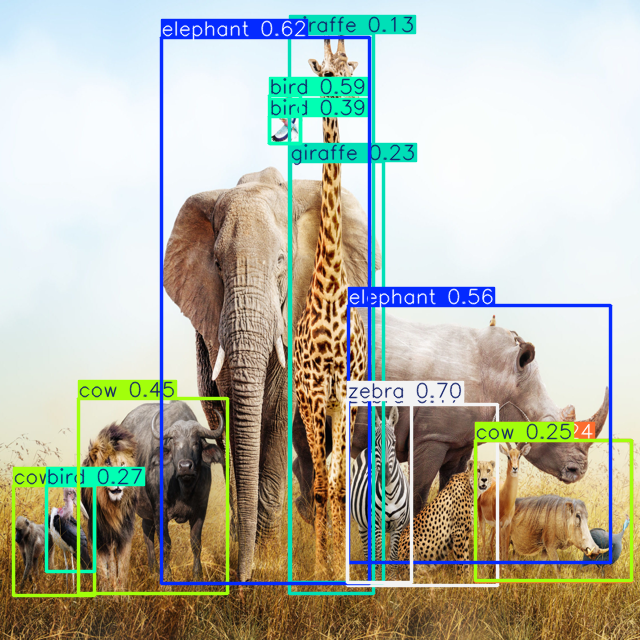

YOLO26n: 11 detections


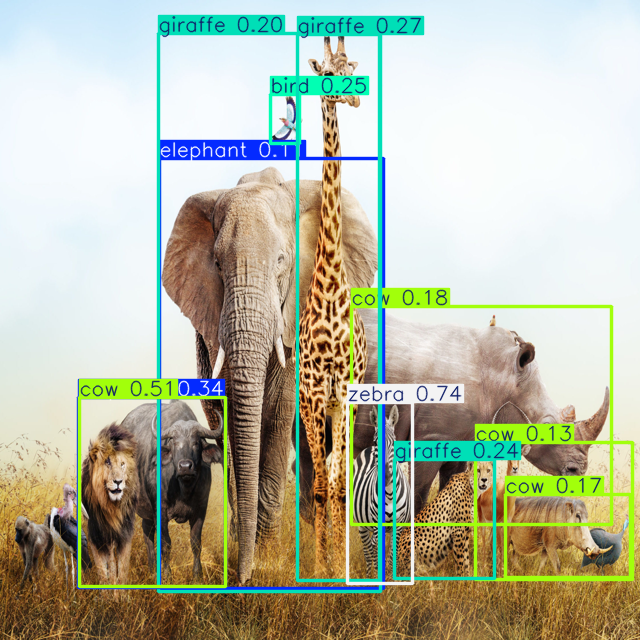

In [7]:
for name, model in models.items():
    results = model.predict(
        source=image,
        conf=0.10,
        imgsz=640,
        verbose=False
    )

    print(f"{name}: {len(results[0].boxes)} detections")
    display(Image.fromarray(results[0].plot()[..., ::-1]))

## 3. Confidence threshold experiment
Observe the difference between displaying more predictions and **learning a new class**.

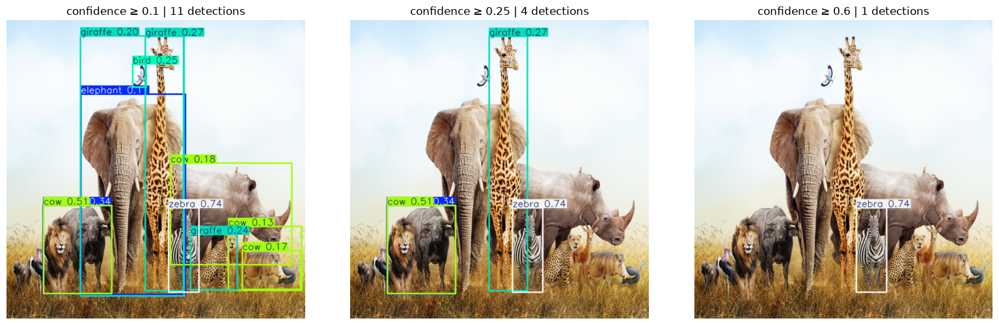

In [8]:
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,conf in zip(axes,[0.1,0.25,0.6]):
    r=models['YOLO26n'].predict(image,conf=conf,imgsz=SIZE,device=DEVICE,verbose=False)[0]
    ax.imshow(r.plot()[...,::-1]);ax.set_title(f'confidence ≥ {conf} | {len(r.boxes)} detections');ax.axis('off')
plt.tight_layout();plt.show()


# Part B — Fine-tune on REAL labeled wildlife images

We use the [Ultralytics African Wildlife detection dataset](https://docs.ultralytics.com/datasets/detect/african-wildlife/), with real photographs and **YOLO-format bounding-box labels** for **buffalo, elephant, rhino, and zebra**.

**Learning question:** Can fine-tuning improve recognition of a *specific domain*? The pretrained COCO model already knows `elephant` and `zebra`, but not separate `buffalo` and `rhino` classes.

## 4. Download the annotated wildlife dataset (automatic)

The dataset downloads into Colab's local `/content` storage **for faster training**. You do not need to put it in Drive. Training outputs and the best checkpoint will be saved to your mounted Drive folder.


In [9]:
from pathlib import Path
import urllib.request, zipfile, shutil, random, yaml

DATA_URL = 'https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip'
ROOT = Path('/content/wildlife_lab')
ROOT.mkdir(parents=True, exist_ok=True)
archive = ROOT / 'african-wildlife.zip'
if not archive.exists():
    print('Downloading official labeled dataset (~100 MB)...')
    urllib.request.urlretrieve(DATA_URL, archive)

# Safe extraction: refuse absolute paths or path traversal.
with zipfile.ZipFile(archive) as z:
    for member in z.infolist():
        target = (ROOT / member.filename).resolve()
        if not target.is_relative_to(ROOT.resolve()):
            raise ValueError(f'Unsafe archive path: {member.filename}')
    z.extractall(ROOT)

candidates = list(ROOT.rglob('images/train'))
assert candidates, 'Expected images/train directory not found in archive'
FULL = candidates[0].parent.parent
print('Dataset root:', FULL)
for split in ('train', 'val', 'test'):
    ims = [p for p in (FULL/'images'/split).iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png'}]
    print(f'{split}: {len(ims)} labeled images available')

Dataset root: /content/wildlife_lab
train: 1052 labeled images available
val: 225 labeled images available
test: 227 labeled images available


## 5. Create a quick classroom subset (reproducible)

The full dataset is available, but this subset reduces training time. Change `TRAIN_N`, `VAL_N`, and `TEST_N` if you have more time. **Never move the same image into two splits.**

In [10]:
TRAIN_N, VAL_N, TEST_N = 180, 45, 45  # increase for better results
CLASS_NAMES = ['buffalo', 'elephant', 'rhino', 'zebra']
SMALL = ROOT/'classroom_subset'
rng = random.Random(42)
for split, limit in [('train',TRAIN_N),('val',VAL_N),('test',TEST_N)]:
    source_images = sorted(p for p in (FULL/'images'/split).iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png'})
    assert len(source_images)>=limit, f'Not enough {split} images'
    selected = rng.sample(source_images, limit)
    (SMALL/'images'/split).mkdir(parents=True,exist_ok=True)
    (SMALL/'labels'/split).mkdir(parents=True,exist_ok=True)
    for img in selected:
        label = FULL/'labels'/split/(img.stem+'.txt')
        shutil.copy2(img,SMALL/'images'/split/img.name)
        if label.exists():
            shutil.copy2(label,SMALL/'labels'/split/label.name)
        else:
            (SMALL/'labels'/split/(img.stem+'.txt')).write_text('')

DATA_YAML = SMALL/'data.yaml'
DATA_YAML.write_text(yaml.safe_dump({'path':str(SMALL),'train':'images/train','val':'images/val','test':'images/test','names':dict(enumerate(CLASS_NAMES))},sort_keys=False))
print(DATA_YAML.read_text())

path: /content/wildlife_lab/classroom_subset
train: images/train
val: images/val
test: images/test
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra



## 6. See the actual labels before training

Each `.txt` file contains rows of `class_id center_x center_y width height`, normalized to values between 0 and 1. Draw these boxes to verify that the labels really match the images.

In [13]:
from PIL import Image, ImageDraw

def draw_ground_truth(img_path):
    img = Image.open(img_path).convert('RGB')
    draw = ImageDraw.Draw(img)

    # Find the corresponding annotation file
    split = img_path.parent.name
    label_path = SMALL / 'labels' / split / f'{img_path.stem}.txt'

    W, H = img.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            cls, cx, cy, w, h = map(float, line.split())

            x1 = (cx - w / 2) * W
            y1 = (cy - h / 2) * H
            x2 = (cx + w / 2) * W
            y2 = (cy + h / 2) * H

            draw.rectangle(
                [x1, y1, x2, y2],
                outline='red',
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                CLASS_NAMES[int(cls)],
                fill='red'
            )

    return img

## 7. Before fine-tuning: inspect predictions on held-out test images

The original COCO model can recognize some animals but does **not** have distinct `buffalo` or `rhino` labels. Compare visually against ground truth; class names can differ.

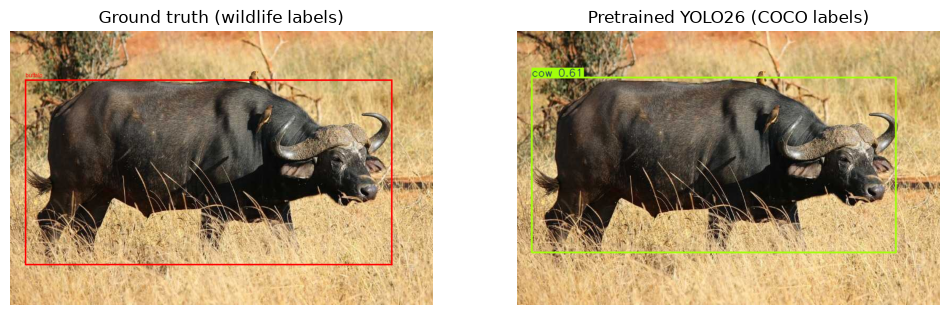

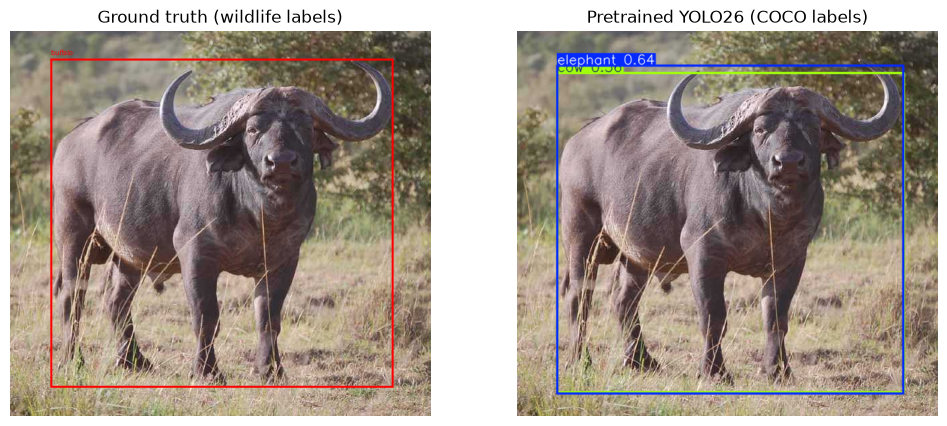

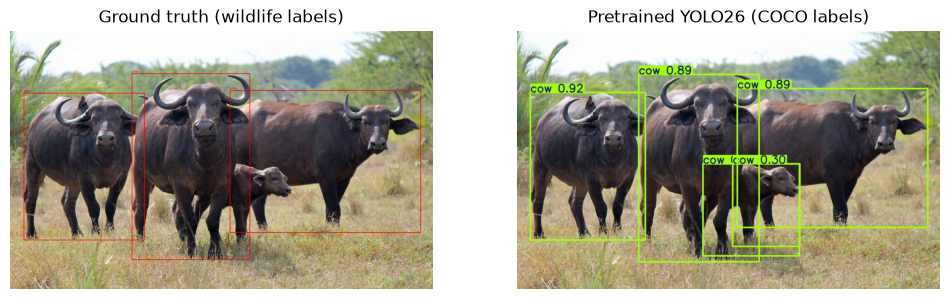

In [14]:
TEST_IMAGES = sorted(p for p in (SMALL/'images'/'test').iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png'})
TEST_EXAMPLES = TEST_IMAGES[:3]
BASELINE = YOLO('yolo26n.pt')
for path in TEST_EXAMPLES:
    pred=BASELINE.predict(source=str(path),conf=0.20,imgsz=640,device=DEVICE,verbose=False)[0]
    fig,axs=plt.subplots(1,2,figsize=(12,5))
    axs[0].imshow(draw_ground_truth(path));axs[0].set_title('Ground truth (wildlife labels)')
    axs[1].imshow(pred.plot()[...,::-1]);axs[1].set_title('Pretrained YOLO26 (COCO labels)')
    for ax in axs:ax.axis('off')
    plt.show()

## 8. Fine-tune YOLO26n on the labeled wildlife subset



In [17]:
from pathlib import Path
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "Please enable a GPU in Colab."

EPOCHS = 8

student_model = YOLO('yolo26n.pt')

train_results = student_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    seed=42,
    project='/content/runs',
    name='wildlife_classroom',
    exist_ok=True,
    plots=True
)

BEST = Path(train_results.save_dir) / 'weights' / 'best.pt'

print("Fine-tuned model saved at:", BEST)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/wildlife_lab/classroom_subset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=wildlife_classroom, nbs=64, nms=None, opset

## 9. Compare before and after on the **same held-out images**

These are **test images**, not training images. Look for new `buffalo`/`rhino` labels and improved localization. The before and after label spaces differ, so avoid comparing raw class counts as though they were identical.

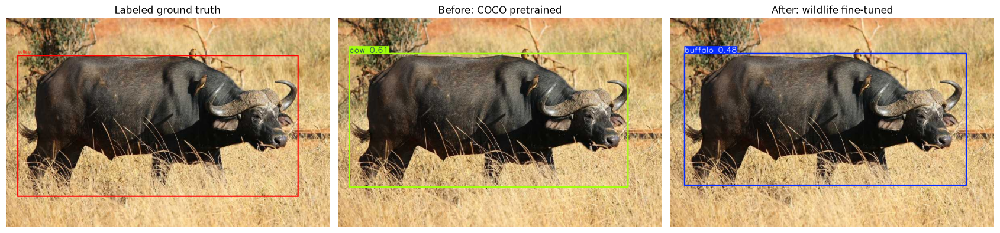

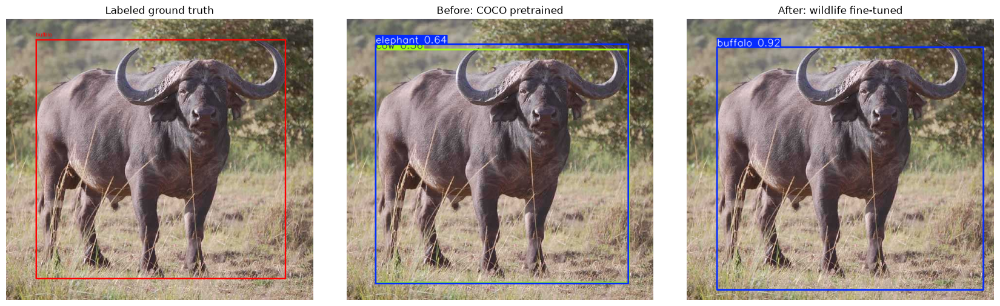

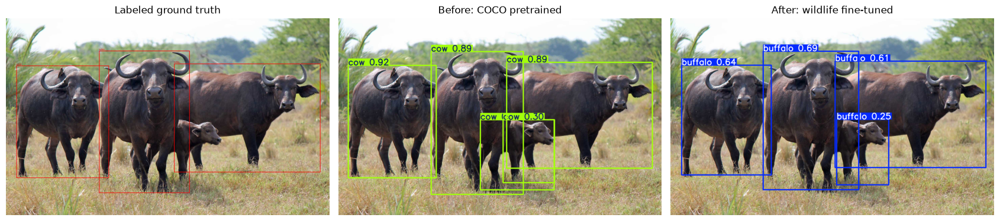

In [18]:
fine_tuned=YOLO(str(BEST))
for path in TEST_EXAMPLES:
    before=BASELINE.predict(str(path),conf=0.20,imgsz=640,device=DEVICE,verbose=False)[0]
    after=fine_tuned.predict(str(path),conf=0.20,imgsz=640,device=DEVICE,verbose=False)[0]
    fig,axs=plt.subplots(1,3,figsize=(17,5))
    axs[0].imshow(draw_ground_truth(path));axs[0].set_title('Labeled ground truth')
    axs[1].imshow(before.plot()[...,::-1]);axs[1].set_title('Before: COCO pretrained')
    axs[2].imshow(after.plot()[...,::-1]);axs[2].set_title('After: wildlife fine-tuned')
    for ax in axs:ax.axis('off')
    plt.tight_layout();plt.show()

## 10. Evaluate on the held-out test split

We selected the best checkpoint using validation data, then measure **mAP on a separate test set**. The small test subset makes results noisy; treat them as classroom measurements, not publishable benchmarks.

In [19]:
metrics = fine_tuned.val(data=str(DATA_YAML),split='test',imgsz=640,device=DEVICE,plots=True)
print(f'Precision: {metrics.box.mp:.3f}')
print(f'Recall: {metrics.box.mr:.3f}')
print(f'mAP@0.50: {metrics.box.map50:.3f}')
print(f'mAP@0.50:0.95: {metrics.box.map:.3f}')

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2417.4±1491.1 MB/s, size: 105.1 KB)
val: Scanning /content/wildlife_lab/classroom_subset/labels/test... 45 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 45/45 2.1Kit/s 0.0s
val: New cache created: /content/wildlife_lab/classroom_subset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.0it/s 1.5s
                   all         45         73      0.751      0.839      0.823      0.619
               buffalo         10         13      0.561          1      0.879       0.73
              elephant         10         16      0.735      0.938      0.808      0.608
                 rhino         11         15      0.814      0.533      0.677      0.513
                 zebra         14         